# Other regressions applied to coronary heart disease

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.interpolate import LSQUnivariateSpline, UnivariateSpline
from scipy.stats import norm
from ipywidgets import interact, FloatSlider

Data from Hosmer, D.W. & Lemeshow, S. (1989) Applied logistic regression. Wiley

Data are ages (in years) and indicator of significant damage in the coronary of 100 people

The response is 0 or 1, and its mean given the age is the probability of coronary heart disease. Before using the logistic regression (notebook `18_logistic_regression_heart_disease`), what happens if we estimate that mean with the regression methods we already know?

In [2]:
dat = pd.read_csv('heart_disease_vs_age.csv')
dat = dat.sort_values('age')

n = len(dat)
x = dat['age'].to_numpy()
y = dat['chd'].to_numpy().astype(int)
X = np.vstack([np.ones(n), x]).T

n_grid = 300
x_grid = np.linspace(x.min(), x.max(), n_grid)
X_grid = np.vstack([np.ones(n_grid), x_grid]).T

To judge the fits, we also compute the proportion of people with the disease by age groups (the groups of Hosmer and Lemeshow).

In [3]:
age_groups = pd.cut(dat['age'], [19, 29, 34, 39, 44, 49, 54, 59, 69])
groups = dat.groupby(age_groups, observed=True).agg(age=('age', 'mean'), chd=('chd', 'mean'), n=('chd', 'size'))
groups.round(3)

,age,chd,n
age,,,
"(19, 29]",25.400,0.100,10
"(29, 34]",32.067,0.133,15
"(34, 39]",36.917,0.250,12
"(39, 44]",42.267,0.333,15
"(44, 49]",47.231,0.462,13
"(49, 54]",51.750,0.625,8
"(54, 59]",56.824,0.824,17
"(59, 69]",63.000,0.700,10


In [4]:
curve_color = '#08519c'   # deep blue for the fitted line
point_color = '#444444'   # neutral grey for observations
group_color = '#c1121f'   # red for the proportions by age group

def plot_fit(ax, y_grid, title, label='Fit', legend=True):
    # Shade the values that cannot be probabilities
    ax.axhspan(1, 1.3, color='#f2d6d8', linewidth=0)
    ax.axhspan(-0.3, 0, color='#f2d6d8', linewidth=0)
    ax.plot(x_grid, y_grid, color=curve_color, linewidth=2.2, label=label)
    ax.scatter(x, y, s=28, color=point_color, alpha=0.35, edgecolor='none', label='Observations')
    ax.scatter(groups['age'], groups['chd'], s=12*groups['n'], color=group_color, edgecolor='white', linewidth=0.8,
               label='Proportion by age group', zorder=3)
    ax.set_xlabel('Age', fontsize=12)
    ax.set_ylabel('Prob. of coronary heart disease', fontsize=12)
    ax.set_ylim(-0.3, 1.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title)
    if legend:
        ax.legend(frameon=False, fontsize=11, loc='center right')

## Linear regression

The line gives negative "probabilities" for the youngest people, and it would go above one a little after 70 years (shaded regions: values that cannot be probabilities).

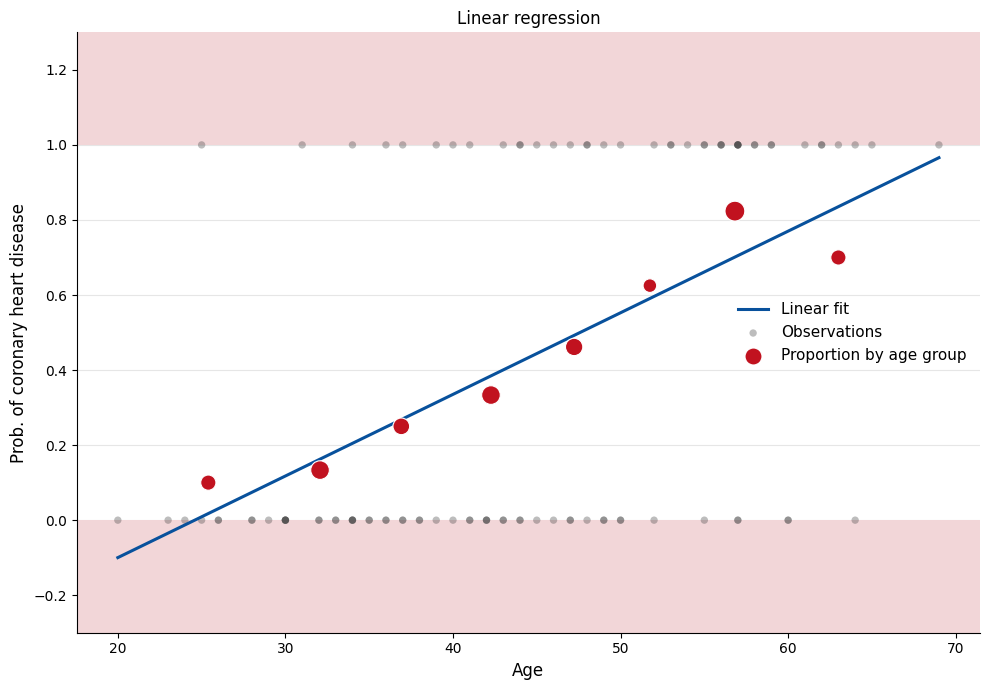

In [5]:
linear_reg = sm.OLS(y, X).fit()
y_linear = linear_reg.predict(X_grid)

fig, ax = plt.subplots(figsize=(10, 7))
plot_fit(ax, y_linear, 'Linear regression', 'Linear fit')
plt.tight_layout()

## Cubic splines

A cubic spline with knots at 40 and 50 years.

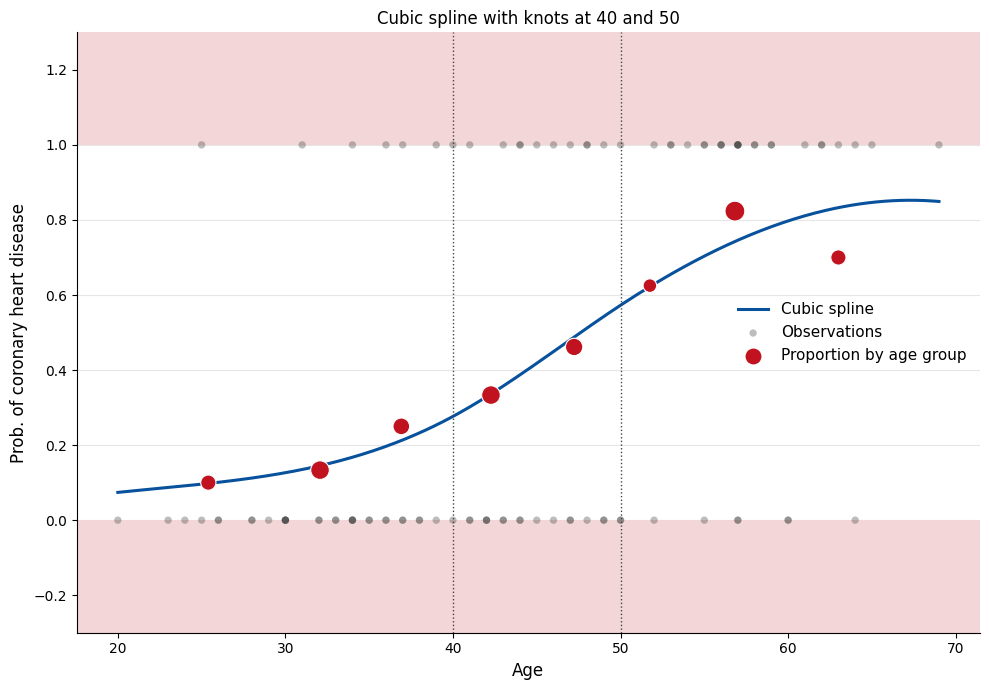

In [6]:
cubic_spline = LSQUnivariateSpline(x, y, t=[40, 50], k=3)
y_spline = cubic_spline(x_grid)

fig, ax = plt.subplots(figsize=(10, 7))
plot_fit(ax, y_spline, 'Cubic spline with knots at 40 and 50', 'Cubic spline')
for k in [40, 50]:
    ax.axvline(k, ls=':', color=point_color, lw=1)
plt.tight_layout()

## Smoothing splines

`UnivariateSpline` with its default smoothing factor (the sum of squared residuals is at most $n$) ends with very few knots.

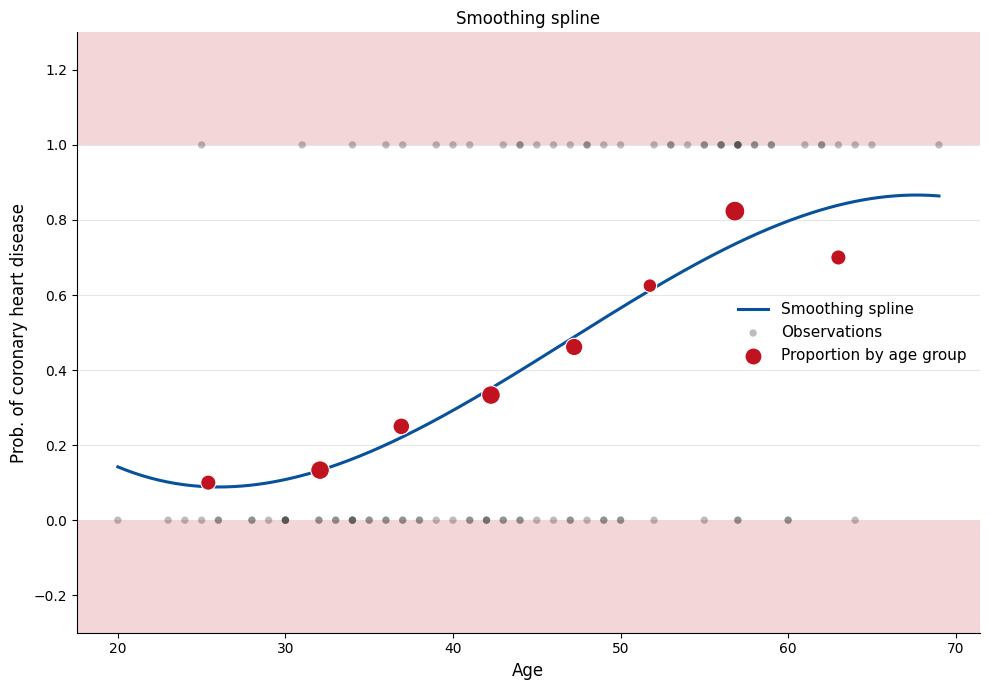

In [7]:
spl = UnivariateSpline(x, y)
y_smooth = spl(x_grid)

fig, ax = plt.subplots(figsize=(10, 7))
plot_fit(ax, y_smooth, 'Smoothing spline', 'Smoothing spline')
plt.tight_layout()

## Local polynomial regression

Local linear regression and the Nadaraya-Watson estimator (local constant), with Gaussian kernel and bandwidth of 5 years.

In [8]:
def local_poly(x0, x, y, h, degree):
    # Estimate of the regression function at x0: weighted least squares around x0
    X_local = np.vstack([(x-x0)**d for d in range(degree+1)]).T
    w = norm.pdf((x-x0)/h)
    WX = X_local*w[:, None]
    return np.linalg.solve(X_local.T @ WX, WX.T @ y)[0]

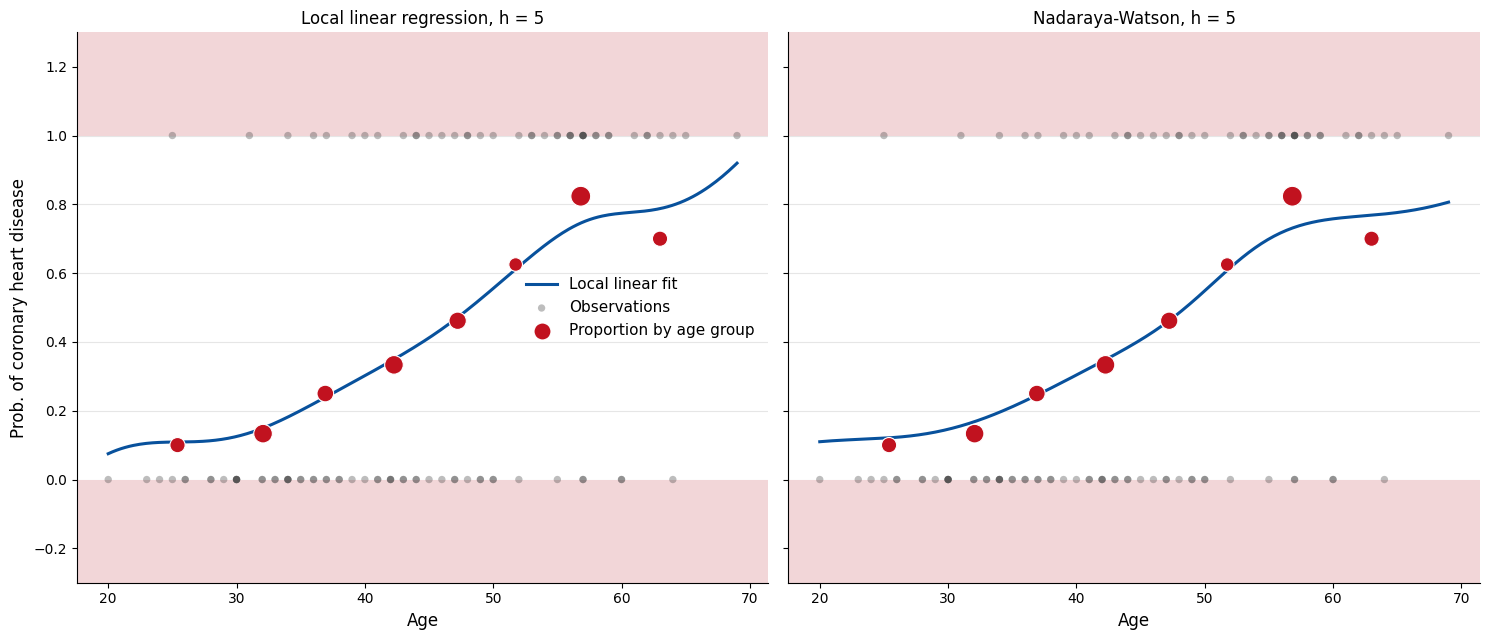

In [9]:
h = 5
y_local_linear = np.array([local_poly(x0, x, y, h, degree=1) for x0 in x_grid])
y_nadaraya_watson = np.array([local_poly(x0, x, y, h, degree=0) for x0 in x_grid])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
plot_fit(axes[0], y_local_linear, f'Local linear regression, h = {h}', 'Local linear fit')
plot_fit(axes[1], y_nadaraya_watson, f'Nadaraya-Watson, h = {h}', 'Nadaraya-Watson', legend=False)
axes[1].set_ylabel('')
plt.tight_layout()

The Nadaraya-Watson estimator is a weighted mean of zeros and ones, so it always stays between 0 and 1; the local linear fit does not have to. Move the slider to change the bandwidth (this cell needs a running kernel).

In [10]:
def interactive_local(h):
    fig, ax = plt.subplots(figsize=(10, 7))
    plot_fit(ax, np.array([local_poly(x0, x, y, h, degree=0) for x0 in x_grid]), f'h = {h:g}', 'Nadaraya-Watson')
    ax.plot(x_grid, np.array([local_poly(x0, x, y, h, degree=1) for x0 in x_grid]), '--', color='#E69F00', lw=2.2,
            label='Local linear fit')
    ax.legend(frameon=False, fontsize=11, loc='center right')
    plt.show()

interact(interactive_local, h=FloatSlider(value=5, min=1, max=20, step=0.5, description='h'));

interactive(children=(FloatSlider(value=5.0, description='h', max=20.0, min=1.0, step=0.5), Output()), _dom_cl…

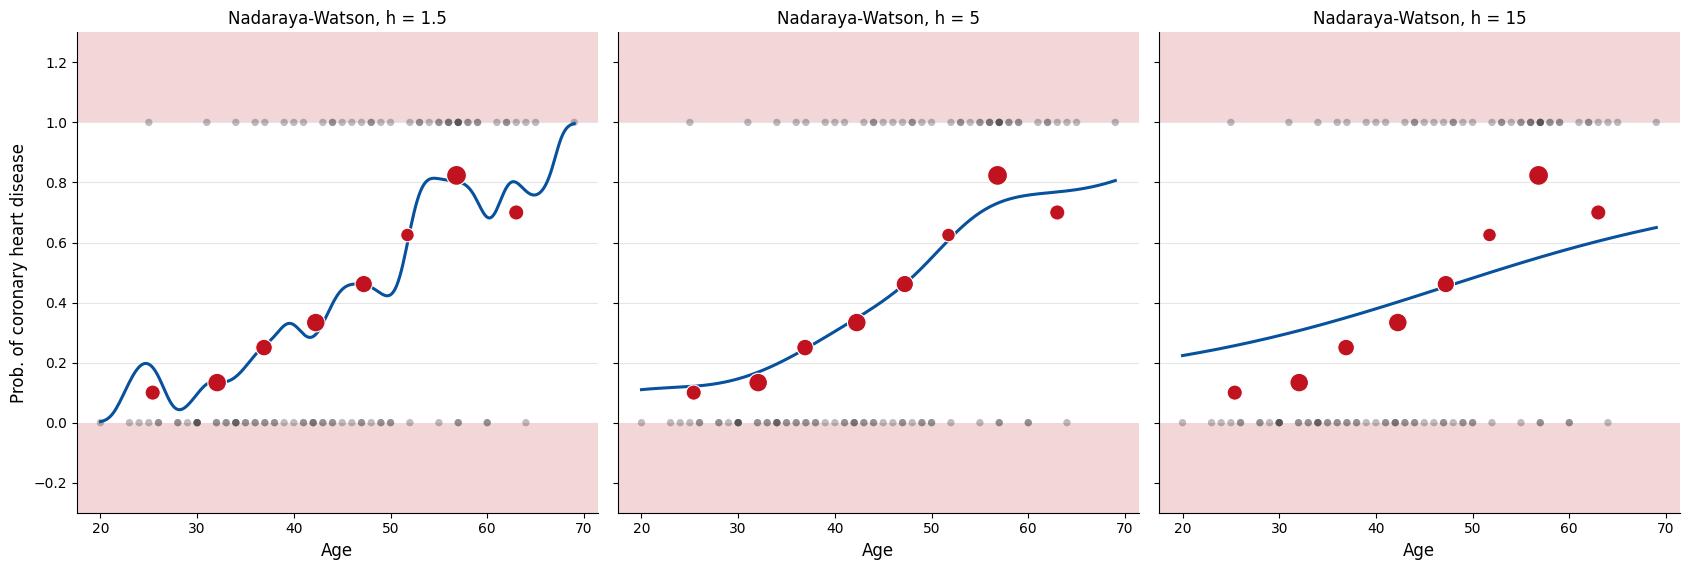

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharey=True)
for ax, h_i in zip(axes, [1.5, 5, 15]):
    plot_fit(ax, np.array([local_poly(x0, x, y, h_i, degree=0) for x0 in x_grid]), f'Nadaraya-Watson, h = {h_i}',
             legend=False)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()

## All together, against the logistic regression

None of these methods knows that the response is a probability. The logistic regression does: it is always between 0 and 1, it is monotone, and it needs only two parameters.

In [12]:
logistic_reg = sm.GLM(y, X, family=sm.families.Binomial()).fit()
y_logistic = logistic_reg.predict(X_grid)

print('Coefficients of the logistic regression:', logistic_reg.params)

Coefficients of the logistic regression: [-5.27844443  0.11032079]


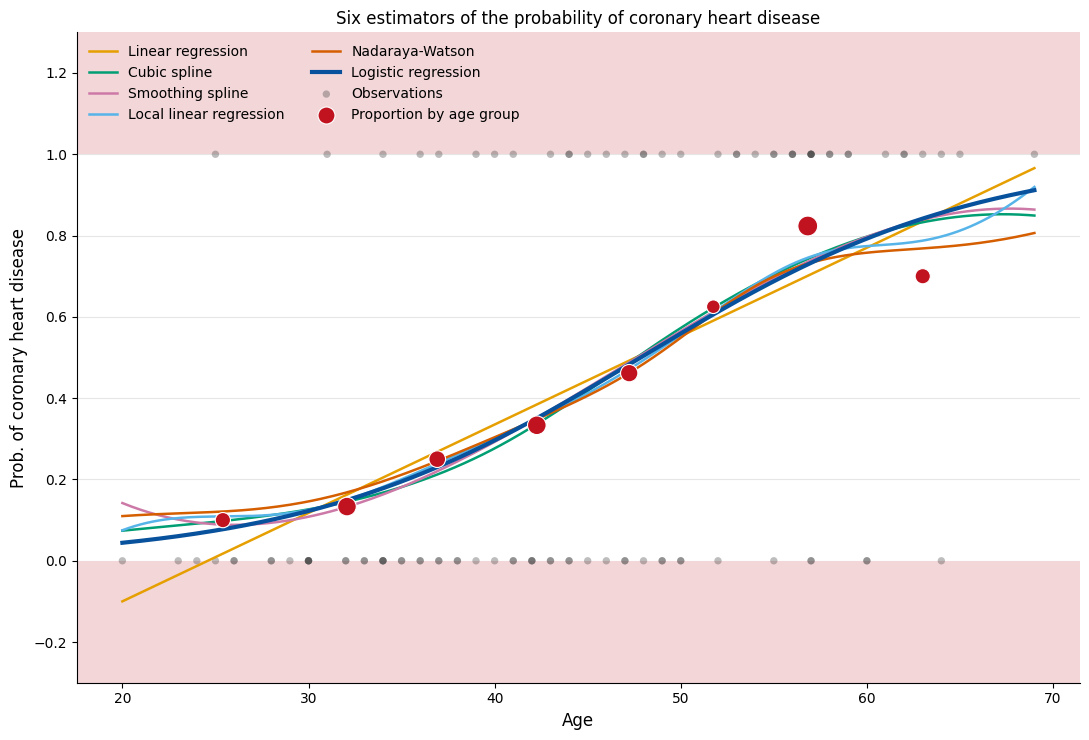

In [13]:
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.axhspan(1, 1.3, color='#f2d6d8', linewidth=0)
ax.axhspan(-0.3, 0, color='#f2d6d8', linewidth=0)

fits = [(y_linear, 'Linear regression', '#E69F00', '-'),
        (y_spline, 'Cubic spline', '#009E73', '-'),
        (y_smooth, 'Smoothing spline', '#CC79A7', '-'),
        (y_local_linear, 'Local linear regression', '#56B4E9', '-'),
        (y_nadaraya_watson, 'Nadaraya-Watson', '#D55E00', '-'),
        (y_logistic, 'Logistic regression', curve_color, '-')]
for y_grid, name, color, ls in fits:
    ax.plot(x_grid, y_grid, ls, color=color, linewidth=3 if name == 'Logistic regression' else 1.8, label=name)
ax.scatter(x, y, s=28, color=point_color, alpha=0.35, edgecolor='none', label='Observations')
ax.scatter(groups['age'], groups['chd'], s=12*groups['n'], color=group_color, edgecolor='white', linewidth=0.8,
           label='Proportion by age group', zorder=3)

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Prob. of coronary heart disease', fontsize=12)
ax.set_ylim(-0.3, 1.3)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title('Six estimators of the probability of coronary heart disease')
ax.legend(frameon=False, fontsize=10, loc='upper left', ncol=2)
plt.tight_layout()